
# Project : SupplySight – Supply Chain Risk Intelligence

Supplier risk scoring, concentration risk, late-delivery prediction and disruption scenarios, with an AI risk memo.

## What this notebook does
- Makes a made-up supplier and shipment dataset (or uses your own suppliers.csv and shipments.csv if you upload them)
- Builds a weighted risk score for every supplier and puts them in High / Medium / Low tiers, then checks the score against real late-delivery history
- Measures country and supplier concentration (HHI)
- Predicts late deliveries with a Gradient Boosting model
- Runs country disruption scenarios to see how much spend is exposed
- Uses Groq AI to write a risk memo with mitigation ideas

## How to run
1. Upload this file to Google Colab (or open it from Drive)
2. Runtime → Run all, or run each cell one by one
3. If a step fails, run the cell again, then restart the runtime once and run again

## Step 1: Install libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn openai

## Step 2: Connect to Groq (the AI part)
Paste your Groq API key when it asks. The key is hidden while you type.

In [2]:
import time
from getpass import getpass
from openai import OpenAI

GROQ_KEY = getpass("Paste your Groq API key: ")
client = OpenAI(api_key=GROQ_KEY, base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"

def ask_llm(question, system="You are a helpful analyst.", model=MODEL):
    for tries in range(3):
        try:
            r = client.chat.completions.create(
                model=model,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
                max_tokens=1500,
                temperature=0.3,
            )
            return r.choices[0].message.content
        except Exception as e:
            print("llm error, trying again:", str(e)[:100])
            time.sleep(5)
    return "LLM not available right now."

print(ask_llm("Say hi in five words."))

Paste your Groq API key: ··········
Hi there, how are you?


## Step 3: Load the data
If you upload `suppliers.csv` and `shipments.csv` to Colab they are used. Otherwise sample data is created.

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
np.random.seed(7)
sns.set_style("whitegrid")

country_risk = {"India": 0.3, "China": 0.5, "Vietnam": 0.35, "Germany": 0.15, "USA": 0.15,
                "Mexico": 0.45, "Turkey": 0.55, "Brazil": 0.5, "Poland": 0.2, "Thailand": 0.4}

def make_suppliers(n=60):
    countries = list(country_risk.keys())
    rows = []
    for i in range(n):
        c = np.random.choice(countries, p=[0.18, 0.22, 0.1, 0.08, 0.08, 0.08, 0.06, 0.06, 0.06, 0.08])
        rows.append({
            "supplier_id": "S" + str(i + 1).zfill(3),
            "country": c,
            "category": np.random.choice(["Electronics", "Raw Material", "Packaging", "Logistics", "Components"]),
            "annual_spend": round(np.random.lognormal(12, 0.8), 0),
            "lead_time_days": int(np.random.randint(7, 70)),
            "on_time_rate": round(np.clip(np.random.normal(0.85, 0.08), 0.5, 0.99), 3),
            "defect_rate": round(np.clip(np.random.normal(0.03, 0.02), 0.001, 0.15), 4),
            "financial_score": int(np.clip(np.random.normal(65, 18), 15, 98)),
            "single_source": int(np.random.rand() < 0.25),
        })
    return pd.DataFrame(rows)

def make_shipments(sup, n=4000):
    rows = []
    for i in range(n):
        s = sup.sample(1).iloc[0]
        promised = int(s["lead_time_days"] + np.random.randint(-3, 4))
        p_late = (1 - s["on_time_rate"]) + country_risk[s["country"]] * 0.15
        late = np.random.rand() < p_late
        actual = promised + (np.random.randint(1, 12) if late else -np.random.randint(0, 3))
        rows.append({"supplier_id": s["supplier_id"], "promised_days": max(promised, 1),
                     "actual_days": max(actual, 1), "late": int(actual > promised)})
    return pd.DataFrame(rows)

if os.path.exists("suppliers.csv") and os.path.exists("shipments.csv"):
    suppliers = pd.read_csv("suppliers.csv")
    shipments = pd.read_csv("shipments.csv")
    print("Using your uploaded files")
else:
    suppliers = make_suppliers()
    shipments = make_shipments(suppliers)
    print("Using sample data")

print(suppliers.shape, shipments.shape)
suppliers.head()

Using sample data
(60, 9) (4000, 4)


,supplier_id,country,category,annual_spend,lead_time_days,on_time_rate,defect_rate,financial_score,single_source
0,S001,India,Raw Material,36164.0,30,0.815,0.0142,65,0
1,S002,Vietnam,Components,119986.0,7,0.916,0.0267,58,0
2,S003,China,Electronics,253638.0,63,0.860,0.0398,55,0
3,S004,Vietnam,Logistics,307229.0,7,0.944,0.0292,48,0
4,S005,Thailand,Packaging,117196.0,14,0.713,0.0439,32,0


## Step 4: Supplier risk score
Each factor is scaled from 0 to 1 (1 = worse). Then a weighted sum gives the risk score out of 100.

risk_tier
Low       24
Medium    24
High      12
Name: count, dtype: int64
   supplier_id   country      category  annual_spend  risk_score risk_tier
12        S013     China    Components      139485.0        71.9      High
28        S029    Mexico   Electronics      197803.0        67.2      High
33        S034  Thailand   Electronics      367123.0        67.2      High
24        S025    Mexico     Logistics      278963.0        67.1      High
4         S005  Thailand     Packaging      117196.0        66.3      High
21        S022     China    Components      403081.0        65.2      High
8         S009  Thailand     Logistics      310339.0        65.1      High
55        S056    Turkey     Logistics      144751.0        62.7      High
27        S028     China  Raw Material      178661.0        60.9      High
32        S033   Vietnam    Components       54554.0        59.5      High


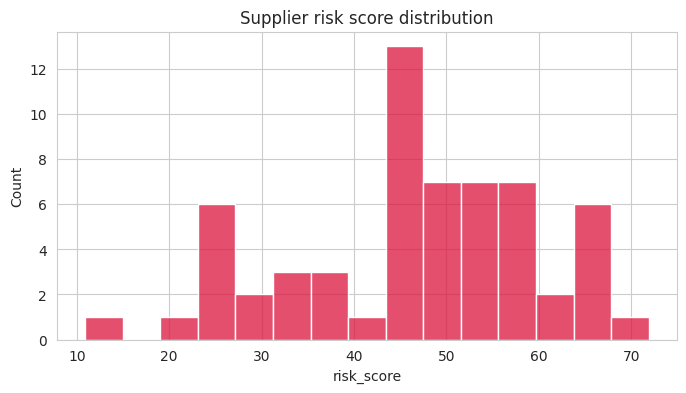

In [4]:
def scale01(col):
    return (col - col.min()) / (col.max() - col.min() + 0.000001)

suppliers["geo_risk"] = suppliers["country"].map(country_risk).fillna(0.4)

weights = {"late_risk": 0.25, "defect_risk": 0.15, "finance_risk": 0.2,
           "leadtime_risk": 0.1, "geo_risk_s": 0.2, "single_source": 0.1}

suppliers["late_risk"] = scale01(1 - suppliers["on_time_rate"])
suppliers["defect_risk"] = scale01(suppliers["defect_rate"])
suppliers["finance_risk"] = scale01(100 - suppliers["financial_score"])
suppliers["leadtime_risk"] = scale01(suppliers["lead_time_days"])
suppliers["geo_risk_s"] = scale01(suppliers["geo_risk"])

suppliers["risk_score"] = 0
for col in weights:
    suppliers["risk_score"] = suppliers["risk_score"] + suppliers[col] * weights[col]
suppliers["risk_score"] = (suppliers["risk_score"] * 100).round(1)

high_cut = suppliers["risk_score"].quantile(0.8)
low_cut = suppliers["risk_score"].quantile(0.4)
def tier(score):
    if score >= high_cut:
        return "High"
    elif score >= low_cut:
        return "Medium"
    return "Low"
suppliers["risk_tier"] = suppliers["risk_score"].apply(tier)

print(suppliers["risk_tier"].value_counts())
print(suppliers.sort_values("risk_score", ascending=False)[["supplier_id", "country", "category", "annual_spend", "risk_score", "risk_tier"]].head(10))

plt.figure(figsize=(8, 4))
sns.histplot(suppliers["risk_score"], bins=15, color="crimson")
plt.title("Supplier risk score distribution")
plt.show()

## Step 4b: Does the risk score match what really happened?
A risk score is only useful if risky suppliers really deliver late more often. We check the score against the shipment history. (With made-up data this is partly true by design, because lateness was generated from on-time rate. With real data it is the real test.)

In [5]:
actual_late = shipments.groupby("supplier_id")["late"].agg(["mean", "count"]).rename(columns={"mean": "actual_late_rate", "count": "shipments"})
check = suppliers.merge(actual_late, on="supplier_id", how="left")
by_tier = check.groupby("risk_tier").agg(suppliers=("supplier_id", "count"), actual_late_rate=("actual_late_rate", "mean")).loc[["High", "Medium", "Low"]]
by_tier["actual_late_rate"] = (by_tier["actual_late_rate"] * 100).round(1)
print("Actual late-delivery % by risk tier:")
print(by_tier)
rank_corr = check["risk_score"].corr(check["actual_late_rate"], method="spearman")
print("\nRank correlation between risk score and actual late rate:", round(rank_corr, 2))
if by_tier.loc["High", "actual_late_rate"] > by_tier.loc["Low", "actual_late_rate"]:
    print("High-risk suppliers do deliver late more often than low-risk ones.")
else:
    print("WARNING: the risk score does not separate late deliveries. Rethink the weights.")

Actual late-delivery % by risk tier:
           suppliers  actual_late_rate
risk_tier                             
High              12              33.5
Medium            24              20.9
Low               24              14.3

Rank correlation between risk score and actual late rate: 0.61
High-risk suppliers do deliver late more often than low-risk ones.


## Step 5: Concentration risk

HHI by country: 1352 -> low concentration (under 1500 = low, 1500 to 2500 = moderate, above 2500 = high)
HHI by supplier: 288 -> low concentration
Top 3 countries share: 51.4 %
Top 10 suppliers share: 41.1 %


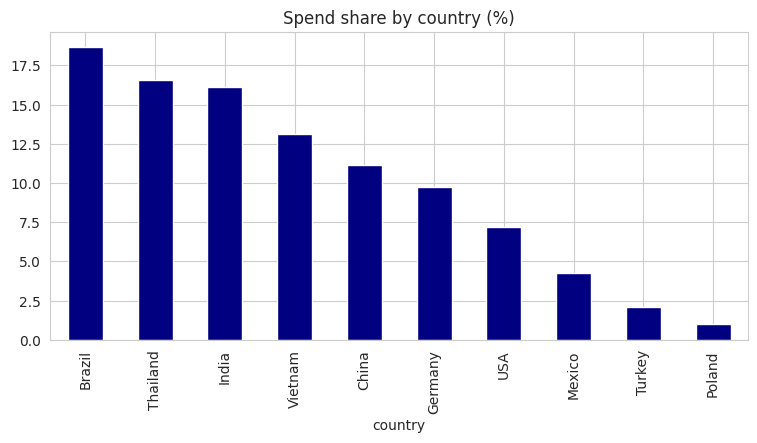


Spend share by risk tier (%):
risk_tier
High      18.3
Low       49.7
Medium    32.1
Name: annual_spend, dtype: float64


In [6]:
total_spend = suppliers["annual_spend"].sum()
country_spend = suppliers.groupby("country")["annual_spend"].sum().sort_values(ascending=False)
country_share = country_spend / total_spend
hhi_country = ((country_share * 100) ** 2).sum()

supplier_share = suppliers.set_index("supplier_id")["annual_spend"] / total_spend
hhi_supplier = ((supplier_share * 100) ** 2).sum()

def hhi_label(h):
    if h < 1500:
        return "low"
    if h <= 2500:
        return "moderate"
    return "high"
hhi_country_label = hhi_label(hhi_country)
hhi_supplier_label = hhi_label(hhi_supplier)
print("HHI by country:", round(hhi_country), "->", hhi_country_label, "concentration (under 1500 = low, 1500 to 2500 = moderate, above 2500 = high)")
print("HHI by supplier:", round(hhi_supplier), "->", hhi_supplier_label, "concentration")
print("Top 3 countries share:", round(country_share.head(3).sum() * 100, 1), "%")
print("Top 10 suppliers share:", round(supplier_share.sort_values(ascending=False).head(10).sum() * 100, 1), "%")

(country_share * 100).plot(kind="bar", figsize=(9, 4), color="navy")
plt.title("Spend share by country (%)")
plt.show()

risk_spend = suppliers.groupby("risk_tier")["annual_spend"].sum() / total_spend * 100
print("\nSpend share by risk tier (%):")
print(risk_spend.round(1))

## Step 6: Predict late deliveries

late rate in data: 20.9 %
baseline accuracy: 0.791
model accuracy: 0.785
model AUC: 0.675
simple rule AUC (just use 1 - on_time_rate): 0.678
late rate among the 10% of shipments the model rates riskiest: 44.6 % (overall: 20.9 %)
The model is not better than the simple rule. The supplier's own on-time rate already tells most of the story.
Accuracy is below always-guess-on-time, so use the model to RANK risk, not to say yes/no.


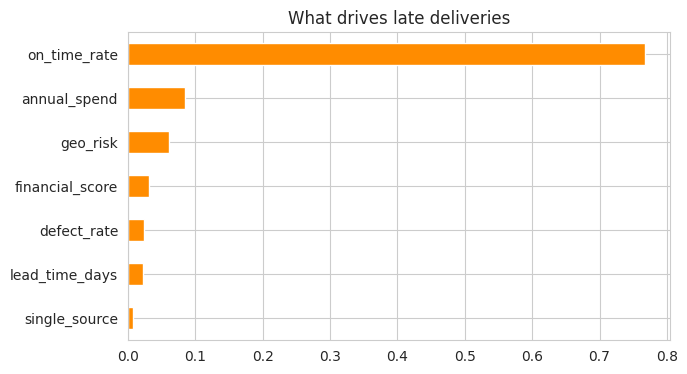

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score

ship = shipments.merge(suppliers, on="supplier_id", how="left")
features = ["lead_time_days", "on_time_rate", "defect_rate", "financial_score", "single_source", "geo_risk", "annual_spend"]
X = ship[features]
y = ship["late"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
gb = GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
prob = gb.predict_proba(X_test)[:, 1]

print("late rate in data:", round(y.mean() * 100, 1), "%")
print("baseline accuracy:", round(max(y_test.mean(), 1 - y_test.mean()), 3))
print("model accuracy:", round(accuracy_score(y_test, gb.predict(X_test)), 3))
model_auc = roc_auc_score(y_test, prob)
rule_auc = roc_auc_score(y_test, 1 - X_test["on_time_rate"])
print("model AUC:", round(model_auc, 3))
print("simple rule AUC (just use 1 - on_time_rate):", round(rule_auc, 3))
top_cut = np.percentile(prob, 90)
top_rate = y_test[prob >= top_cut].mean()
print("late rate among the 10% of shipments the model rates riskiest:", round(top_rate * 100, 1), "% (overall:", round(y_test.mean() * 100, 1), "%)")
if model_auc <= rule_auc + 0.01:
    print("The model is not better than the simple rule. The supplier's own on-time rate already tells most of the story.")
if accuracy_score(y_test, gb.predict(X_test)) < max(y_test.mean(), 1 - y_test.mean()):
    print("Accuracy is below always-guess-on-time, so use the model to RANK risk, not to say yes/no.")

imp = pd.Series(gb.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7, 4), color="darkorange")
plt.title("What drives late deliveries")
plt.show()

## Step 7: Disruption scenarios
What if all suppliers in one country stop delivering? How much spend is exposed and how many single-source parts are hit?

    country  suppliers  spend_exposed_pct  single_source_suppliers  \
0   Vietnam         11               13.1                        5   
1     India          9               16.1                        3   
2    Brazil          5               18.7                        1   
3  Thailand          8               16.6                        0   
4    Mexico          3                4.3                        1   
5     China          7               11.2                        0   
6   Germany          8                9.8                        2   
7    Turkey          2                2.1                        1   
8       USA          5                7.2                        0   
9    Poland          2                1.0                        0   

   avg_risk_score  priority_score  
0            48.2            36.0  
1            42.3            29.7  
2            46.4            26.3  
3            55.0            24.8  
4            62.8            24.0  
5            

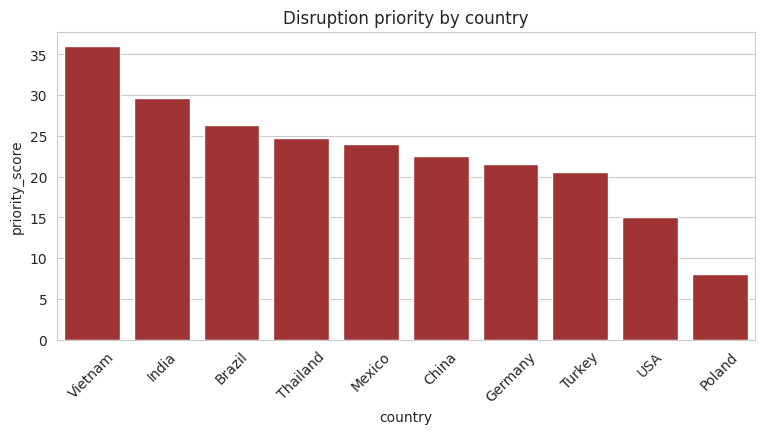

In [8]:
rows = []
for c in suppliers["country"].unique():
    sub = suppliers[suppliers["country"] == c]
    rows.append({
        "country": c,
        "suppliers": len(sub),
        "spend_exposed_pct": round(sub["annual_spend"].sum() / total_spend * 100, 1),
        "single_source_suppliers": int(sub["single_source"].sum()),
        "avg_risk_score": round(sub["risk_score"].mean(), 1),
    })
scenario = pd.DataFrame(rows).sort_values("spend_exposed_pct", ascending=False)
scenario["priority_score"] = (scenario["spend_exposed_pct"] * 0.5 + scenario["single_source_suppliers"] * 3 + scenario["avg_risk_score"] * 0.3).round(1)
scenario = scenario.sort_values("priority_score", ascending=False).reset_index(drop=True)
print(scenario)

plt.figure(figsize=(9, 4))
sns.barplot(data=scenario, x="country", y="priority_score", color="firebrick")
plt.xticks(rotation=45)
plt.title("Disruption priority by country")
plt.show()

## Step 8: AI risk memo (Groq)

In [9]:
top5 = suppliers.sort_values("risk_score", ascending=False).head(5)
top5_text = top5[["supplier_id", "country", "category", "annual_spend", "on_time_rate", "defect_rate", "financial_score", "single_source", "risk_score"]].to_dict("records")
top5_share = top5["annual_spend"].sum() / total_spend * 100

text = f"""
Total suppliers: {len(suppliers)}, total annual spend: {total_spend:,.0f} (no currency is given, do not add a currency symbol)
HHI by country: {hhi_country:.0f}, which is {hhi_country_label} concentration (under 1500 is low)
Top 3 countries share of spend: {country_share.head(3).sum()*100:.1f}%
The 5 riskiest suppliers below hold {top5_share:.1f}% of total spend
Highest priority disruption country: {scenario.loc[0, 'country']}
Late-delivery model AUC: {model_auc:.2f} versus {rule_auc:.2f} for the simple rule 1 minus on-time rate (a weak model, say so)
Top 5 risky suppliers: {top5_text}
"""
memo = ask_llm("Write a supply chain risk memo for the procurement head. Give a short summary, then for each of the top 5 suppliers give 1-2 practical mitigation actions. Use only the numbers given here, do not calculate new numbers, do not invent dates or internal targets, and do not add a currency symbol. The data is made-up sample data, say that once at the end.\n" + text,
               system="You are a supply chain risk analyst. Do not invent numbers.")
print(memo)

**To:** Head of Procurement  
**From:** Supply Chain Risk Analyst  
**Date:** 9 Oct 2026  
**Subject:** Risk Overview & Immediate Mitigation Steps for Our Five Highest‑Risk Suppliers  

---

### Executive Summary
- **Supplier landscape:** 60 active suppliers support a total annual spend of **13,754,940**.  
- **Market concentration:** Herfindahl‑Hirschman Index (HHI) by country is **1352**, indicating a low‑concentration sourcing base (under 1500 is low).  
- **Geographic exposure:** The top three source countries account for **51.4 %** of spend.  
- **Risk concentration:** The five riskiest suppliers together represent **8.0 %** of total spend.  
- **Disruption hotspot:** Vietnam is flagged as the highest‑priority disruption country.  
- **Delivery‑performance modeling:** The late‑delivery model AUC is **0.68**, identical to the simple rule “1 – on‑time rate,” confirming that the current predictive model adds no value and is weak.  

Given these points, we should focus on strengthenin

## Step 9: Key insights and export

In [10]:
worst = suppliers.sort_values("risk_score", ascending=False).iloc[0]
print("KEY INSIGHTS (calculated from this run)")
print("1. High-risk suppliers:", int((suppliers["risk_tier"] == "High").sum()), "holding", round(risk_spend.get("High", 0), 1), "% of spend")
print("2. Highest risk supplier:", worst["supplier_id"], "from", worst["country"], "- score", worst["risk_score"])
print("3. Top country by spend:", country_share.index[0], "-", round(country_share.iloc[0] * 100, 1), "%")
print("4. Single-source suppliers:", int(suppliers["single_source"].sum()), "out of", len(suppliers))
print("5. Biggest disruption priority:", scenario.loc[0, "country"], "(the priority formula uses assumed weights)")
print("6. Risk score check: high-risk tier late rate", by_tier.loc["High", "actual_late_rate"], "% vs low-risk tier", by_tier.loc["Low", "actual_late_rate"], "%")
print("7. Late-delivery model AUC", round(model_auc, 3), "vs simple on-time-rate rule", round(rule_auc, 3))
print("8. Country concentration is", hhi_country_label, "(HHI", round(hhi_country), ")")
print("9. This notebook uses made-up supplier data unless you upload suppliers.csv and shipments.csv")

suppliers.to_csv("supplysight_suppliers_scored.csv", index=False)
scenario.to_csv("supplysight_scenarios.csv", index=False)
print("\nSaved supplysight_suppliers_scored.csv and supplysight_scenarios.csv")

KEY INSIGHTS (calculated from this run)
1. High-risk suppliers: 12 holding 18.3 % of spend
2. Highest risk supplier: S013 from China - score 71.9
3. Top country by spend: Brazil - 18.7 %
4. Single-source suppliers: 13 out of 60
5. Biggest disruption priority: Vietnam (the priority formula uses assumed weights)
6. Risk score check: high-risk tier late rate 33.5 % vs low-risk tier 14.3 %
7. Late-delivery model AUC 0.675 vs simple on-time-rate rule 0.678
8. Country concentration is low (HHI 1352 )
9. This notebook uses made-up supplier data unless you upload suppliers.csv and shipments.csv

Saved supplysight_suppliers_scored.csv and supplysight_scenarios.csv



Built by **Akshat Kesharwani** | [GitHub](https://github.com/akshatkesharwani-info) | [Portfolio](https://akshatkesharwani-info.github.io/)